# Shell Scripts & Scheduling with cron

A **shell script** saves a sequence of commands in a file, so a task runs the same way every time. **cron** runs scripts on a schedule: every night, every 15 minutes, every Monday. Together they automate backups, data downloads, report generation and clean-up.

**After this lesson you can:**

1. Write robust bash scripts: `set -euo pipefail`, variables, quoting, functions, arguments.
2. Clean up with `trap`, log with timestamps and return meaningful exit codes.
3. Write cron schedules and predict when they run.
4. Decide when to use cron, systemd timers or a workflow orchestrator.

In [1]:
import os
import subprocess
import tempfile
from pathlib import Path

WORK = Path(tempfile.mkdtemp())          # a folder on the Linux file system (not on a Windows drive)
REPO = Path.cwd().parent                 # the course repository: real data for some examples

class Output(str):
    """The text output of a command; the notebook does not display it a second time."""
    def _ipython_display_(self):
        pass

def sh(cmd: str, cwd: Path = WORK, quiet: bool = False, check: bool = False) -> Output:
    """Run a command with bash, print the command and its output."""
    r = subprocess.run(["bash", "-c", cmd], cwd=cwd, capture_output=True, text=True)
    shorten = lambda t: t.replace(str(WORK), "<work>").replace(str(REPO), "<repo>")
    out = shorten((r.stdout + r.stderr).rstrip())
    if not quiet:
        print(f"$ {shorten(cmd)}" + (f"\n{out}" if out else ""))
    if check and r.returncode:
        raise RuntimeError(f"command failed with exit code {r.returncode}")
    return Output(r.stdout)

## 1. A Robust Script Template

```bash
#!/usr/bin/env bash
set -euo pipefail          # -e: exit on error, -u: error on unset variables, -o pipefail: see Lesson 02
IFS=$'\n\t'                # split words only on newlines and tabs, not on spaces
```

Rules for safe scripts:

1. **Quote variables**: `"$file"`, never `$file`. Without quotes, a file name with a space becomes two arguments.
2. Use `local` variables inside functions.
3. Check the arguments and print a usage message.
4. Use `trap` to clean up temporary files, also when the script fails.
5. Write messages to stderr with a timestamp; exit with `0` on success and non-zero on failure.

The cell writes a backup script that follows these rules. It archives a folder, keeps the newest *N* archives and deletes older ones (**rotation**).

In [2]:
backup = WORK / "backup.sh"
backup.write_text(r"""#!/usr/bin/env bash
set -euo pipefail
IFS=$'\n\t'

usage() { echo "usage: $0 SOURCE_DIR DEST_DIR [KEEP=3]" >&2; exit 2; }
log()   { echo "$(date '+%Y-%m-%d %H:%M:%S') [backup] $*" >&2; }

[[ $# -lt 2 ]] && usage
src="$1"; dest="$2"; keep="${3:-3}"
[[ -d "$src" ]] || { log "source '$src' does not exist"; exit 1; }
mkdir -p "$dest"

tmp="$(mktemp)"
trap 'rm -f "$tmp"' EXIT                       # always remove the temporary file

stamp="$(date +%Y%m%d-%H%M%S-%N)"
tar -czf "$tmp" -C "$(dirname "$src")" "$(basename "$src")"
mv "$tmp" "$dest/backup-$stamp.tar.gz"
log "created backup-$stamp.tar.gz ($(du -h "$dest/backup-$stamp.tar.gz" | cut -f1))"

# rotation: keep the newest $keep archives
count=0
while IFS= read -r old; do
  count=$((count + 1))
  if (( count > keep )); then rm -- "$old"; log "deleted old $(basename "$old")"; fi
done < <(ls -1t "$dest"/backup-*.tar.gz)
""")
backup.chmod(0o755)
(WORK / "my data").mkdir()
(WORK / "my data" / "sales 2025.csv").write_text("id,amount\n1,10\n2,20\n")
sh("./backup.sh")                                          # no arguments: usage message, exit code 2
sh("./backup.sh missing-folder archives; echo exit code: $?")
for _ in range(5):
    sh("./backup.sh 'my data' archives 3")
sh("ls -1 archives && tar -tzf \"$(ls -1t archives/*.tar.gz | head -1)\"")

$ ./backup.sh
usage: ./backup.sh SOURCE_DIR DEST_DIR [KEEP=3]
$ ./backup.sh missing-folder archives; echo exit code: $?
exit code: 1
2026-11-16 17:03:01 [backup] source 'missing-folder' does not exist
$ ./backup.sh 'my data' archives 3
2026-11-16 17:03:01 [backup] created backup-20261116-170301-852339629.tar.gz (4.0K)
$ ./backup.sh 'my data' archives 3
2026-11-16 17:03:01 [backup] created backup-20261116-170301-889654990.tar.gz (4.0K)
$ ./backup.sh 'my data' archives 3
2026-11-16 17:03:01 [backup] created backup-20261116-170301-928108680.tar.gz (4.0K)
$ ./backup.sh 'my data' archives 3
2026-11-16 17:03:01 [backup] created backup-20261116-170301-964658478.tar.gz (4.0K)
2026-11-16 17:03:01 [backup] deleted old backup-20261116-170301-852339629.tar.gz


$ ./backup.sh 'my data' archives 3
2026-11-16 17:03:02 [backup] created backup-20261116-170302-009023505.tar.gz (4.0K)
2026-11-16 17:03:02 [backup] deleted old backup-20261116-170301-889654990.tar.gz
$ ls -1 archives && tar -tzf "$(ls -1t archives/*.tar.gz | head -1)"
backup-20261116-170301-928108680.tar.gz
backup-20261116-170301-964658478.tar.gz
backup-20261116-170302-009023505.tar.gz
my data/
my data/sales 2025.csv


The folder name contains a space (`my data`), and the script handles it because every variable is quoted. After five runs, only the three newest archives remain.

## 2. cron Schedules

A crontab line has five time fields and a command:

```
┌──── minute (0-59)
│ ┌──── hour (0-23)
│ │ ┌──── day of month (1-31)
│ │ │ ┌──── month (1-12)
│ │ │ │ ┌──── day of week (0-6, 0 = Sunday)
│ │ │ │ │
30 2 * * *   /opt/jobs/backup.sh /data /backups 7 >> /var/log/backup.log 2>&1
```

| Expression | Meaning |
| :--- | :--- |
| `*/15 * * * *` | every 15 minutes |
| `0 9-17 * * 1-5` | every hour from 9:00 to 17:00, Monday to Friday |
| `0 0 1 * *` | at midnight on the first day of each month |
| `30 2 * * 0` | at 02:30 every Sunday |

Edit your schedule with `crontab -e`; list it with `crontab -l`. cron runs commands with a minimal environment: use absolute paths and redirect the output to a log file. In a crontab line, `%` means "new line", so write `\%` (for example `date +\%F`).

The function below parses a cron expression and lists when it runs. It shows how cron reads the fields.

In [3]:
from datetime import datetime, timedelta

def parse_field(field: str, low: int, high: int) -> set[int]:
    values = set()
    for part in field.split(","):
        step = 1
        if "/" in part:
            part, step = part.split("/")
            step = int(step)
        if part == "*":
            start, end = low, high
        elif "-" in part:
            start, end = map(int, part.split("-"))
        else:
            start = end = int(part)
        values.update(range(start, end + 1, step))
    return values

def next_runs(expr: str, start: datetime, until: datetime) -> list[datetime]:
    minute, hour, dom, month, dow = expr.split()
    m, h = parse_field(minute, 0, 59), parse_field(hour, 0, 23)
    d, mo, w = parse_field(dom, 1, 31), parse_field(month, 1, 12), parse_field(dow, 0, 6)
    t, runs = start.replace(second=0, microsecond=0), []
    while t < until:
        if t.minute in m and t.hour in h and t.day in d and t.month in mo and (t.weekday() + 1) % 7 in w:
            runs.append(t)
        t += timedelta(minutes=1)
    return runs

monday = datetime(2025, 6, 2)                 # a Monday
for expr in ["0 9-17 * * 1-5", "30 2 * * *", "*/15 * * * *"]:
    runs = next_runs(expr, monday, monday + timedelta(days=7))
    print(f"{expr:<16} {len(runs):4d} runs in one week; first: {[r.strftime('%a %H:%M') for r in runs[:3]]}")

0 9-17 * * 1-5     45 runs in one week; first: ['Mon 09:00', 'Mon 10:00', 'Mon 11:00']
30 2 * * *          7 runs in one week; first: ['Mon 02:30', 'Tue 02:30', 'Wed 02:30']
*/15 * * * *      672 runs in one week; first: ['Mon 00:00', 'Mon 00:15', 'Mon 00:30']


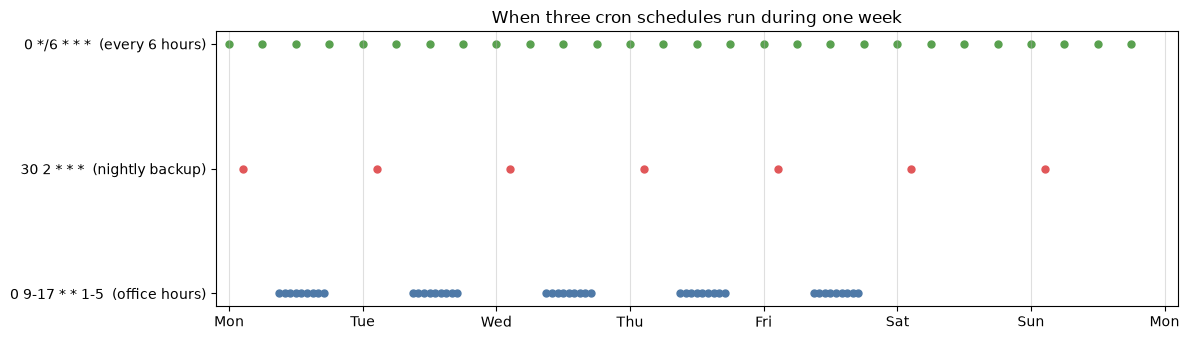

In [4]:
import matplotlib.pyplot as plt

schedules = {"0 9-17 * * 1-5  (office hours)": "#4E79A7", "30 2 * * *  (nightly backup)": "#E15759",
             "0 */6 * * *  (every 6 hours)": "#59A14F"}
fig, ax = plt.subplots(figsize=(12, 3.5))
for row, (label, color) in enumerate(schedules.items()):
    runs = next_runs(label.split("  ")[0], monday, monday + timedelta(days=7))
    ax.scatter([(r - monday).total_seconds() / 86400 for r in runs], [row] * len(runs), color=color, s=25)
ax.set_yticks(range(len(schedules)), list(schedules))
ax.set_xticks(range(8), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun", "Mon"])
ax.set(title="When three cron schedules run during one week", xlim=(-0.1, 7.1))
ax.grid(axis="x", alpha=0.4)
plt.tight_layout()
plt.show()

## 3. Install a Real cron Job

The cell checks whether a cron daemon runs on this machine. If it does, it installs a job that runs every minute, waits until the job ran, shows the log and removes the job again.

In [5]:
import time

cron_running = bool(sh("pgrep -x cron || pgrep -x crond", quiet=True).strip())
print("cron daemon running:", cron_running)
if cron_running:
    marker = WORK / "cron_ran.log"
    # In a crontab line, % means "new line": escape it as \% (a common cron mistake).
    sh(f"(crontab -l 2>/dev/null; echo '* * * * * date \"+\\%H:\\%M:\\%S cron job ran\" >> {marker}') | crontab -")
    sh("crontab -l | tail -1")
    for _ in range(75):                       # wait up to 75 s for the next full minute
        if marker.exists():
            break
        time.sleep(1)
    print(marker.read_text() if marker.exists() else "the job did not run within 75 s")
    sh(f"crontab -l | grep -v '{marker}' | crontab - ; crontab -l 2>/dev/null | grep -c cron_ran || true")
else:
    print("Start cron (for example `sudo service cron start`) to run this part.")

cron daemon running: True


$ (crontab -l 2>/dev/null; echo '* * * * * date "+\%H:\%M:\%S cron job ran" >> <work>/cron_ran.log') | crontab -
$ crontab -l | tail -1
* * * * * date "+\%H:\%M:\%S cron job ran" >> <work>/cron_ran.log


17:04:04 cron job ran

$ crontab -l | grep -v '<work>/cron_ran.log' | crontab - ; crontab -l 2>/dev/null | grep -c cron_ran || true
0


## 4. cron, systemd Timers or an Orchestrator?

| Tool | Strengths | Limits |
| :--- | :--- | :--- |
| **cron** | everywhere, simple | no retries, no dependencies between jobs, logs only if you redirect them |
| **systemd timers** | logs in `journalctl`, runs missed jobs after a reboot (`Persistent=true`), resource limits | Linux with systemd only |
| **Kubernetes CronJob** | containers, history, retries | needs a cluster (M32) |
| **Airflow / Dagster / Prefect** | dependencies between tasks, retries, backfills, monitoring UI | more infrastructure (M11) |

*Insight: Start every script with `set -euo pipefail`, quote every variable, log to stderr and exit with a meaningful code. Use cron for independent, simple jobs; when jobs depend on each other or need retries and monitoring, move them to an orchestrator.*

## Real-World Use Case or Analogy

A shell script is a **written procedure** that a night-shift worker follows step by step; cron is the **alarm clock** that wakes the worker at the right time. A good procedure says what to do when something goes wrong (exit codes, `trap`) and writes a report (logs), so the morning team knows what happened.

Small companies run many data tasks this way: a nightly `pg_dump` backup with rotation, a script that downloads exchange rates every hour, a weekly clean-up of old files. When the number of jobs and their dependencies grow, the team moves them into Airflow or Dagster (M11).